In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

X, y = make_moons(n_samples=600, noise=0.25, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED))

In [33]:
INITIAL_SIZE = 30
QUERY_SIZE = 20
N_ITERATIONS = 10

Query Strategies: Random, Margin,K-Means 

Idee: Random als Baseline, vergleich von zufälligen DP und aus gefählen
Frühe Phase K-Means, möglichst unterschiedliche Bereiche des Datensatzes kennenlernen.
Spätere Phase Margin, gezielt unsichere Punkte an der Entscheidungsgrenze auswählen.

In [34]:
def random_sampling(unlabeled_idx, query_size, rng):
    return rng.choice(unlabeled_idx, size=query_size, replace=False)


def margin_sampling(clf, X_train, unlabeled_idx, query_size):

    probabilities = clf.predict_proba(X_train[unlabeled_idx])

    sorted_probs = np.sort(probabilities, axis=1)

    margins = sorted_probs[:, -1] - sorted_probs[:, -2]

    selected_positions = np.argsort(margins)[:query_size]

    return unlabeled_idx[selected_positions]


def kmeans_sampling(X_train, unlabeled_idx, query_size, seed):

    # Skalieren für die distanzbasierte Clusterbildung
    scaler = StandardScaler()
    X_pool = scaler.fit_transform(X_train[unlabeled_idx])

    kmeans = KMeans(n_clusters=query_size, random_state=seed, n_init=10)

    cluster_labels = kmeans.fit_predict(X_pool)

    selected_positions = []

    for cluster_id in range(query_size):
        members = np.where(cluster_labels == cluster_id)[0]

        center = kmeans.cluster_centers_[cluster_id]

        distances = np.linalg.norm(X_pool[members] - center, axis=1)

        closest = members[np.argmin(distances)]

        selected_positions.append(closest)

    return unlabeled_idx[selected_positions]

In [ ]:
def run_experiment(strategy, seed=42, switch_at=None):

    rng = np.random.default_rng(seed)

    # Identische initiale Labels für alle Strategien
    initial_idx = np.concatenate(
        [
            rng.choice(np.where(y_train == 0)[0], 15, replace=False),
            rng.choice(np.where(y_train == 1)[0], 15, replace=False),
        ]
    )

    labeled_idx = initial_idx.copy()

    unlabeled_idx = np.setdiff1d(np.arange(len(X_train)), labeled_idx)

    results = []

    for iteration in range(N_ITERATIONS + 1):
        clf = clone(model)
        clf.fit(X_train[labeled_idx], y_train[labeled_idx])

        predictions = clf.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        results.append(
            {
                "Strategy": strategy,
                "Switch": switch_at,
                "Iteration": iteration,
                "Labels": len(labeled_idx),
                "Accuracy": accuracy,
            }
        )

        if iteration == N_ITERATIONS:
            break

        # Strategie für die nächste Query-Runde
        if strategy == "Random":
            selected = random_sampling(unlabeled_idx, QUERY_SIZE, rng)

        elif strategy == "K-Means":
            selected = kmeans_sampling(X_train, unlabeled_idx, QUERY_SIZE, seed + iteration)

        elif strategy == "Margin":
            selected = margin_sampling(clf, X_train, unlabeled_idx, QUERY_SIZE)

        elif strategy == "Hybrid":
            if iteration < switch_at:
                selected = kmeans_sampling(X_train, unlabeled_idx, QUERY_SIZE, seed + iteration)
            else:
                selected = margin_sampling(clf, X_train, unlabeled_idx, QUERY_SIZE)

        else:
            raise ValueError("Unknown strategy")

        # Ausgewählte Punkte erhalten ihre Labels
        labeled_idx = np.concatenate([labeled_idx, selected])

        # Punkte aus dem ungelabelten Pool entfernen
        unlabeled_idx = np.setdiff1d(unlabeled_idx, selected)

    return pd.DataFrame(results)

In [36]:
random_df = run_experiment("Random", seed=SEED)
kmeans_df = run_experiment("K-Means", seed=SEED)
margin_df = run_experiment("Margin", seed=SEED)

hybrid_early_df = run_experiment("Hybrid", seed=SEED, switch_at=3)

hybrid_late_df = run_experiment("Hybrid", seed=SEED, switch_at=7)

experiments = {
    "Random": random_df,
    "K-Means": kmeans_df,
    "Margin": margin_df,
    "Hybrid (switch=3)": hybrid_early_df,
    "Hybrid (switch=7)": hybrid_late_df,
}

Visualisieren

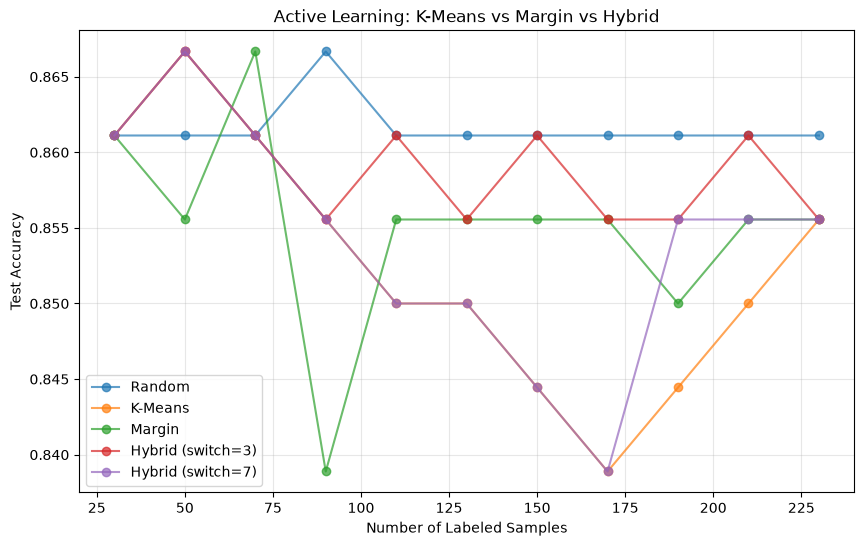

In [37]:
plt.figure(figsize=(10, 6))

for name, data in experiments.items():
    plt.plot(data["Labels"], data["Accuracy"], marker="o", label=name, linestyle="-", alpha=0.7)


plt.xlabel("Number of Labeled Samples")
plt.ylabel("Test Accuracy")
plt.title("Active Learning: K-Means vs Margin vs Hybrid")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Mit AULC (Area Under the Learning Curve): Fläche unter der Accuracy-Lernkurve. Sie misst, wie gut ein Modell im Durchschnitt über das gesamte Labelbudget hinweg abschneidet.

Eine höhere AULC bedeutet: Die Strategie erreicht über die Trainingsrunden hinweg insgesamt eine höhere Accuracy

In [38]:
switch_results = []
switch_curves = {}

for switch in range(N_ITERATIONS + 1):
    df_switch = run_experiment(strategy="Hybrid", seed=SEED, switch_at=switch)

    # Normalisierte Fläche unter der Learning Curve
    aulc = np.trapezoid(df_switch["Accuracy"], df_switch["Labels"]) / (
        df_switch["Labels"].iloc[-1] - df_switch["Labels"].iloc[0]
    )

    switch_results.append({"Switch": switch, "AULC": aulc, "Final Accuracy": df_switch["Accuracy"].iloc[-1]})

    switch_curves[switch] = df_switch

switch_df = pd.DataFrame(switch_results)

display(switch_df.sort_values("AULC", ascending=False))

,Switch,AULC,Final Accuracy
3,3,0.859167,0.855556
4,4,0.858333,0.850000
5,5,0.857500,0.855556
2,2,0.856944,0.855556
6,6,0.855833,0.855556
1,1,0.855278,0.855556
0,0,0.854722,0.855556
7,7,0.853611,0.855556
8,8,0.852500,0.855556
10,10,0.851944,0.855556


Visualisieren:

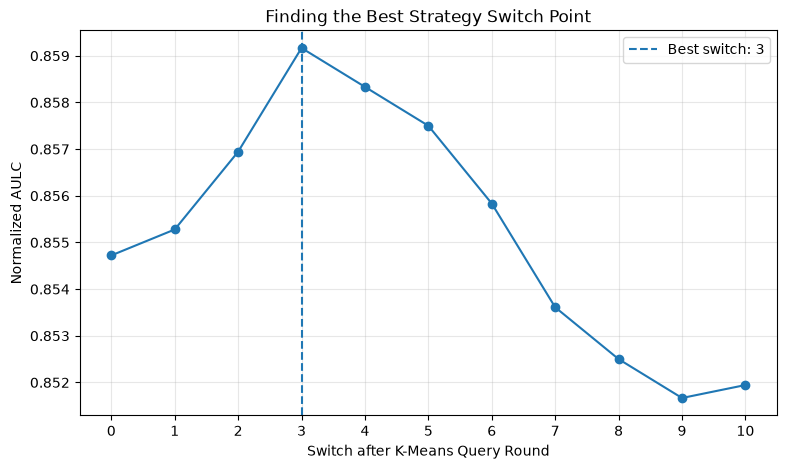

Best switch: 3


In [39]:
best_switch = int(switch_df.loc[switch_df["AULC"].idxmax(), "Switch"])

plt.figure(figsize=(9, 5))

plt.plot(switch_df["Switch"], switch_df["AULC"], marker="o")

plt.axvline(best_switch, linestyle="--", label=f"Best switch: {best_switch}")

plt.xlabel("Switch after K-Means Query Round")
plt.ylabel("Normalized AULC")
plt.title("Finding the Best Strategy Switch Point")

plt.xticks(range(N_ITERATIONS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best switch:", best_switch)